# Who beat their expected goals? Premier League 2020/21

Question: which players and teams scored more (or less) than the quality of their chances
suggested, and how well does expected goals (xG) actually predict goals?

About xG: every shot gets a probability of becoming a goal, based on where and how it was
taken. Add them up and you get the number of goals an average finisher would have scored from the
same chances. Scoring more than your xG means finishing better than average (or getting lucky).

Data: `EPL_20_21.csv` from the Kaggle dataset
[English Premier League (2020-21)](https://www.kaggle.com/datasets/rajatrc1705/english-premier-league202021)
(CC0), one row per player per club in the 2020/21 season (532 rows,
20 clubs): minutes, goals, assists, penalties, cards, and xG / xA.

Contents
1. Setup and data checks
2. Who finished above and below their xG?
3. Clinical finishers per 90 minutes
4. Playmakers: assists vs expected assists
5. Teams: goals vs xG, and discipline
6. Does xG predict goals? (regression)
7. Do forwards get better chances than midfielders? (t-test)
8. Finding player roles with PCA and k-means
9. Comparing the stars (radar charts)
10. Conclusions and limitations

## 1. Setup and data checks

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from pathlib import Path

# One consistent chart style for the whole notebook
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b4b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

df = pd.read_csv("EPL_20_21.csv")
print(df.shape)
df.head()

(532, 18)


,Name,Club,Nationality,Position,Age,Matches,Starts,Mins,Goals,Assists,Passes_Attempted,Perc_Passes_Completed,Penalty_Goals,Penalty_Attempted,xG,xA,Yellow_Cards,Red_Cards
0,Mason Mount,Chelsea,ENG,"MF,FW",21,36,32,2890,6,5,1881,82.3,1,1,0.21,0.24,2,0
1,Edouard Mendy,Chelsea,SEN,GK,28,31,31,2745,0,0,1007,84.6,0,0,0.00,0.00,2,0
2,Timo Werner,Chelsea,GER,FW,24,35,29,2602,6,8,826,77.2,0,0,0.41,0.21,2,0
3,Ben Chilwell,Chelsea,ENG,DF,23,27,27,2286,3,5,1806,78.6,0,0,0.10,0.11,3,0
4,Reece James,Chelsea,ENG,DF,20,32,25,2373,1,2,1987,85.0,0,0,0.06,0.12,3,0


In [2]:
print("Missing values:", df.isna().sum().sum())
print("Clubs:", df["Club"].nunique())
df["Position"].value_counts()

Missing values: 0
Clubs: 20


Position
DF       178
MF       108
FW        81
FW,MF     47
GK        42
MF,FW     36
DF,MF     15
MF,DF     13
FW,DF      6
DF,FW      6
Name: count, dtype: int64

Two things to sort out before any analysis:

- `xG` and `xA` are per 90 minutes, not season totals. Check: if we convert them to totals
  (`xG × Mins / 90`), the league's total xG should be close to the league's total goals.
- Positions can be combined, like `"FW,MF"`. A filter like `Position == "FW"` would silently drop
  those 83 players. I use the first listed position as the player's main position instead.

In [3]:
df["xG_total"] = df["xG"] * df["Mins"] / 90
df["xA_total"] = df["xA"] * df["Mins"] / 90
print(f"Total goals: {df['Goals'].sum()}   Total xG (converted): {df['xG_total'].sum():.0f}")

df["Main_Position"] = df["Position"].str.split(",").str[0]
df["Main_Position"].value_counts()

Total goals: 986   Total xG (converted): 1014


Main_Position
DF    199
MF    157
FW    134
GK     42
Name: count, dtype: int64

The totals match (986 vs about 1014), so the per-90 reading is right.

Penalties: a penalty is worth about 0.76 xG and is scored most of the time, so penalty takers look
like better finishers than they are. For finishing I use *non-penalty* goals (npG) and *non-penalty*
xG (npxG), subtracting 0.76 xG for each penalty taken.

In [4]:
PEN_XG = 0.76
df["npG"] = df["Goals"] - df["Penalty_Goals"]
df["npxG"] = (df["xG_total"] - PEN_XG * df["Penalty_Attempted"]).clip(lower=0)
df["G_minus_xG"] = df["npG"] - df["npxG"]
df["A_minus_xA"] = df["Assists"] - df["xA_total"]

## 2. Who finished above and below their xG?

Each dot is a player. The diagonal is "scored exactly what the chances were worth". Above the line
means finishing better than expected, below means worse.

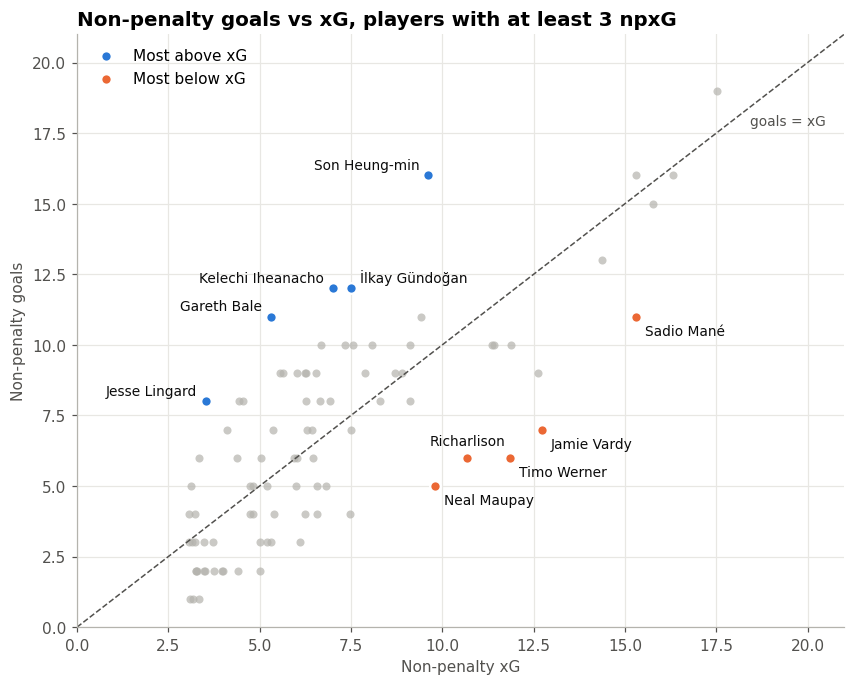

In [5]:
shooters = df[df["npxG"] >= 3]          # enough chances to say something
over = shooters.nlargest(5, "G_minus_xG")
under = shooters.nsmallest(5, "G_minus_xG")

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(shooters["npxG"], shooters["npG"], s=28, color=GREY, alpha=0.7, linewidths=0)
ax.scatter(over["npxG"], over["npG"], s=48, color=BLUE, edgecolor="white", linewidth=1.5, label="Most above xG")
ax.scatter(under["npxG"], under["npG"], s=48, color=ORANGE, edgecolor="white", linewidth=1.5, label="Most below xG")
lim = max(shooters["npxG"].max(), shooters["npG"].max()) + 2
ax.plot([0, lim], [0, lim], color=MUTED, linewidth=1, linestyle="--")
ax.text(lim - 0.5, lim - 3.2, "goals = xG", color=MUTED, ha="right", fontsize=9)

# Label positions: above-left for overperformers, below-right for underperformers,
# with a few nudges where names would collide
NUDGE = {"İlkay Gündoğan": (6, 4, "left"), "Richarlison": (0, 8, "center")}
for _, r in pd.concat([over, under]).iterrows():
    default = (-6, 4, "right") if r["G_minus_xG"] > 0 else (6, -12, "left")
    dx, dy, ha = NUDGE.get(r["Name"], default)
    ax.annotate(r["Name"], (r["npxG"], r["npG"]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, fontsize=9, color=INK)

ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Non-penalty xG", ylabel="Non-penalty goals",
       title="Non-penalty goals vs xG, players with at least 3 npxG")
ax.legend(loc="upper left", frameon=False)
fig.savefig(FIG / "goals_vs_xg.png")
plt.show()

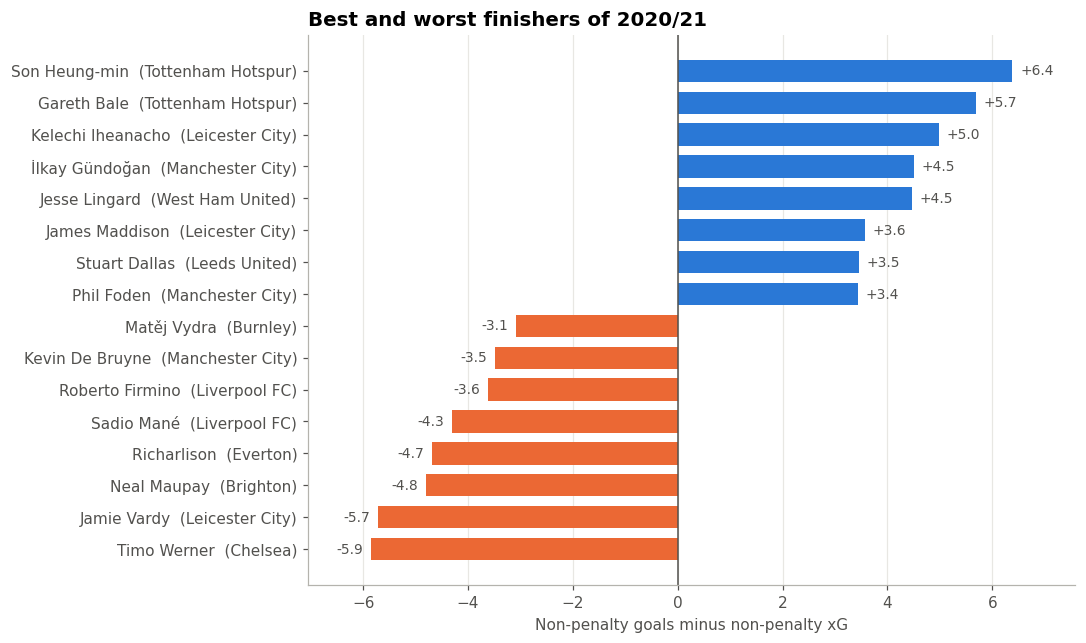

,Name,Club,npG,npxG,G_minus_xG
161,Son Heung-min,Tottenham Hotspur,16,9.6,6.4
175,Gareth Bale,Tottenham Hotspur,11,5.3,5.7
120,Kelechi Iheanacho,Leicester City,12,7.0,5.0
145,Jesse Lingard,West Ham United,8,3.5,4.5
33,İlkay Gündoğan,Manchester City,12,7.5,4.5
115,James Maddison,Leicester City,8,4.4,3.6
212,Stuart Dallas,Leeds United,8,4.5,3.5
39,Phil Foden,Manchester City,9,5.6,3.4
432,Matěj Vydra,Burnley,3,6.1,-3.1
34,Kevin De Bruyne,Manchester City,4,7.5,-3.5


In [6]:
top = pd.concat([shooters.nlargest(8, "G_minus_xG"), shooters.nsmallest(8, "G_minus_xG")])
top = top.sort_values("G_minus_xG")

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = np.where(top["G_minus_xG"] > 0, BLUE, ORANGE)
ax.barh(top["Name"] + "  (" + top["Club"] + ")", top["G_minus_xG"], color=colors, height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
for y, v in enumerate(top["G_minus_xG"]):
    ax.text(v + (0.15 if v > 0 else -0.15), y, f"{v:+.1f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9, color=MUTED)
ax.set(xlabel="Non-penalty goals minus non-penalty xG", title="Best and worst finishers of 2020/21")
ax.grid(axis="y", visible=False)
ax.set_xlim(top["G_minus_xG"].min() - 1.2, top["G_minus_xG"].max() + 1.2)
fig.savefig(FIG / "finishing_over_under.png")
plt.show()

top[["Name", "Club", "npG", "npxG", "G_minus_xG"]].round(1).sort_values("G_minus_xG", ascending=False)

- Son Heung-min (+6.4) and Gareth Bale (+5.7), both at Tottenham, scored far more than their
  chances were worth.
- Timo Werner in his first Chelsea season is the clearest underperformer: about 12 npxG, 6 goals.
  Jamie Vardy did the same, even though he was the league's top scorer the season before.

## 3. Clinical finishers per 90 minutes

Goals per 90 minutes rewards players who score a lot in the time they get. A minimum of
900 minutes (ten full games) keeps out players with one goal in a cameo appearance.

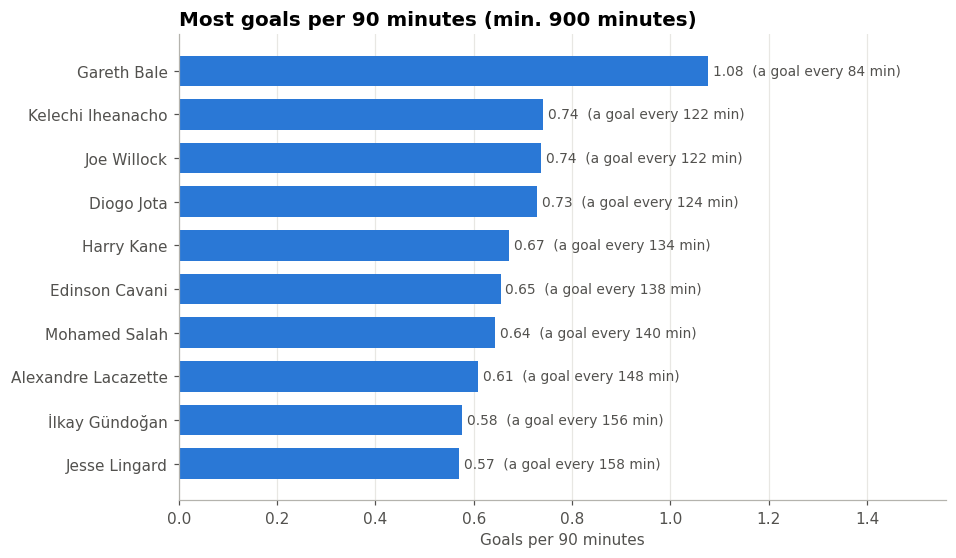

In [7]:
regulars = df[df["Mins"] >= 900].copy()
regulars["Goals_per_90"] = regulars["Goals"] / regulars["Mins"] * 90
regulars["Mins_per_goal"] = regulars["Mins"] / regulars["Goals"].replace(0, np.nan)
best = regulars.nlargest(10, "Goals_per_90").sort_values("Goals_per_90")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(best["Name"], best["Goals_per_90"], color=BLUE, height=0.7)
for y, (g, m) in enumerate(zip(best["Goals_per_90"], best["Mins_per_goal"])):
    ax.text(g + 0.01, y, f"{g:.2f}  (a goal every {m:.0f} min)", va="center", fontsize=9, color=MUTED)
ax.set(xlabel="Goals per 90 minutes", title="Most goals per 90 minutes (min. 900 minutes)")
ax.set_xlim(0, best["Goals_per_90"].max() * 1.45)
ax.grid(axis="y", visible=False)
plt.show()

Gareth Bale scored a goal every 84 minutes, but in only 920 minutes. Harry Kane is the most impressive
over a full season: a goal every 134 minutes across 3,082 minutes, plus 14 assists.

## 4. Playmakers: assists vs expected assists

xA measures how good the passes were: the xG of the shots a player set up. A player with high xA but few
assists created good chances that teammates didn't finish.

In [8]:
creators = df[df["xA_total"] >= 2]
unlucky = creators.nsmallest(6, "A_minus_xA")
lucky = creators.nlargest(6, "A_minus_xA")
pd.concat([lucky, unlucky])[["Name", "Club", "Assists", "xA_total", "A_minus_xA"]].round(1)

,Name,Club,Assists,xA_total,A_minus_xA
162,Harry Kane,Tottenham Hotspur,14,7.5,6.5
54,Marcus Rashford,Manchester United,9,3.6,5.4
110,Jamie Vardy,Leicester City,9,5.0,4.0
345,Eberechi Eze,Crystal Palace,6,2.8,3.2
214,Patrick Bamford,Leeds United,7,4.1,2.9
366,James Ward-Prowse,Southampton,7,4.2,2.8
320,Adama Traoré,Wolverhampton Wanderers,2,5.3,-3.3
454,Ivan Cavaleiro,Fulham,0,3.3,-3.3
0,Mason Mount,Chelsea,5,7.7,-2.7
57,Fred,Manchester United,0,2.7,-2.7


Adama Traoré and Mason Mount set up chances worth 5 to 8 assists but got 2 and 5. Harry Kane is
the opposite: 14 assists from about 7.5 xA, helped by Son Heung-min finishing so well
(section 2), so assists also depend on the teammate.

## 5. Teams: goals vs xG, and discipline

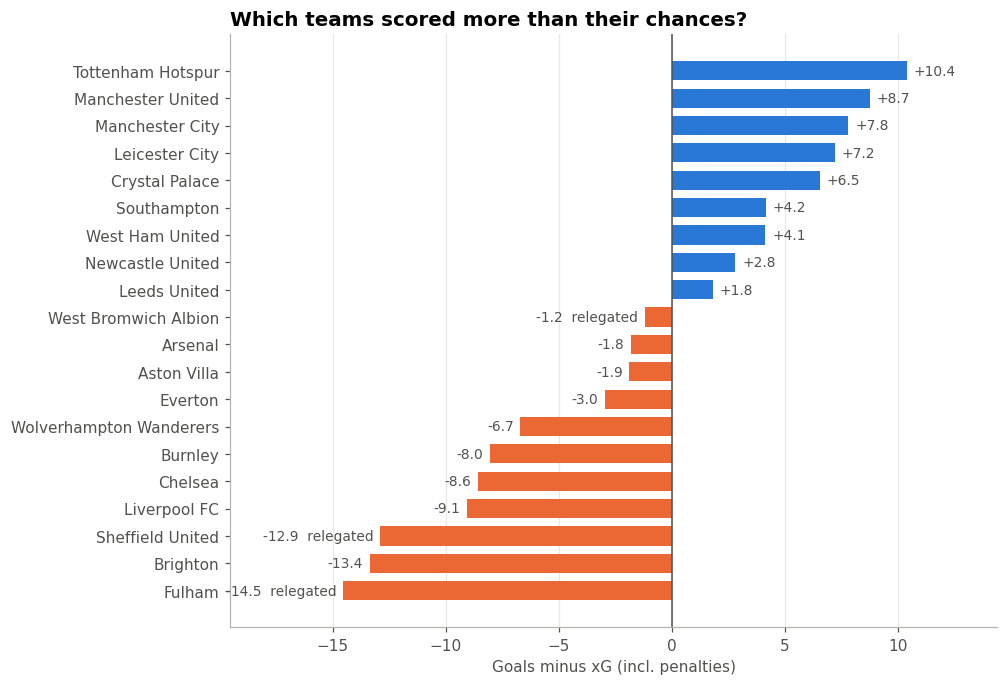

In [9]:
teams = df.groupby("Club").agg(Goals=("Goals", "sum"), xG=("xG_total", "sum"),
                               Yellow=("Yellow_Cards", "sum"), Red=("Red_Cards", "sum"))
teams["Goals_minus_xG"] = teams["Goals"] - teams["xG"]
teams = teams.sort_values("Goals_minus_xG")

RELEGATED = {"Fulham", "West Bromwich Albion", "Sheffield United"}
fig, ax = plt.subplots(figsize=(9, 7))
colors = np.where(teams["Goals_minus_xG"] > 0, BLUE, ORANGE)
ax.barh(teams.index, teams["Goals_minus_xG"], color=colors, height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
for y, (club, v) in enumerate(teams["Goals_minus_xG"].items()):
    label = f"{v:+.1f}" + ("  relegated" if club in RELEGATED else "")
    ax.text(v + (0.3 if v > 0 else -0.3), y, label, va="center",
            ha="left" if v > 0 else "right", fontsize=9, color=MUTED)
ax.set(xlabel="Goals minus xG (incl. penalties)", title="Which teams scored more than their chances?")
ax.set_xlim(teams["Goals_minus_xG"].min() - 5, teams["Goals_minus_xG"].max() + 4)
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "teams_goals_vs_xg.png")
plt.show()

Fulham and Sheffield United were relegated after scoring 13 to 15 goals fewer than their chances were
worth. At the top, Tottenham, Manchester United and Manchester City all scored more than expected.

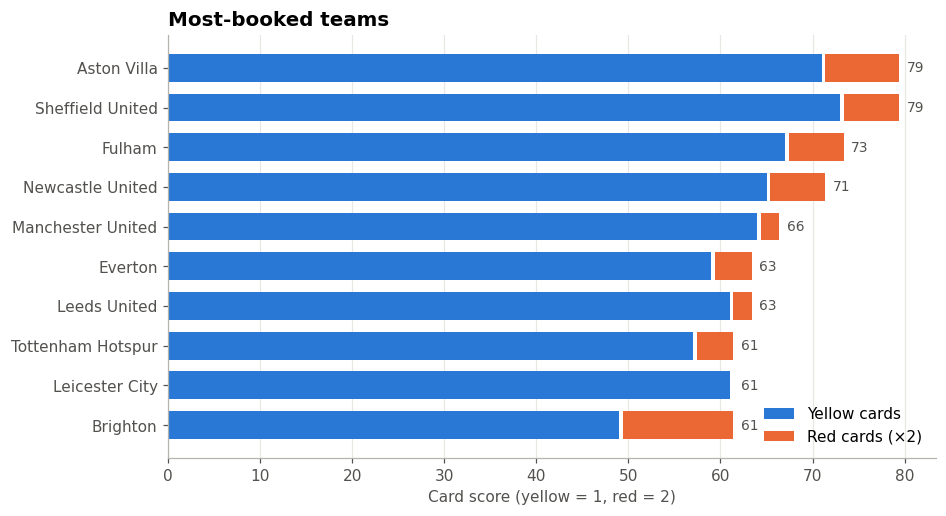

In [10]:
# Discipline: a red card counts as two yellows
teams["Card_score"] = teams["Yellow"] + 2 * teams["Red"]
cards = teams.sort_values("Card_score", ascending=False).head(10).sort_values("Card_score")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cards.index, cards["Yellow"], color=BLUE, height=0.7, label="Yellow cards")
ax.barh(cards.index, 2 * cards["Red"], left=cards["Yellow"] + 0.4, color=ORANGE, height=0.7,
        label="Red cards (×2)")
for y, s in enumerate(cards["Card_score"]):
    ax.text(s + 1.2, y, str(s), va="center", fontsize=9, color=MUTED)
ax.set(xlabel="Card score (yellow = 1, red = 2)", title="Most-booked teams")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
plt.show()

## 6. Does xG predict goals?

A linear regression of season goals on season xG. If xG works, the slope should be close to 1
(one extra xG gives one extra goal), and the intercept close to 0.

In [11]:
X = sm.add_constant(df["xG_total"])
ols = sm.OLS(df["Goals"], X).fit()
print(ols.summary().tables[1])
print(f"\nR² = {ols.rsquared:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0328      0.062     -0.532      0.595      -0.154       0.088
xG_total       0.9900      0.017     58.957      0.000       0.957       1.023

R² = 0.868


In [12]:
# The same model checked on players it hasn't seen: 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    df[["xG_total"]], df["Goals"], test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Slope: {model.coef_[0]:.2f}   Intercept: {model.intercept_:.2f}")
print(f"Test R²: {r2_score(y_test, y_pred):.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} goals")

Slope: 1.00   Intercept: -0.03
Test R²: 0.831
Test RMSE: 1.23 goals


The slope is about 0.99 and xG explains about 87% of the variation in goals. On unseen players
the prediction is off by about 1.2 goals on average. So xG is a very good predictor over a season,
and the players in section 2 stand out precisely because they are far from this line.

## 7. Do forwards get better chances than midfielders?

Hypotheses, for players with at least 900 minutes:
- H₀: forwards and midfielders have the same mean xG per 90.
- H₁: the means differ (two-tailed), α = 0.05.

I use Welch's t-test, which doesn't assume the two groups have the same variance.

Forwards:    n = 77, mean xG/90 = 0.32
Midfielders: n = 103, mean xG/90 = 0.11
t = 10.65, p = 2.0e-19


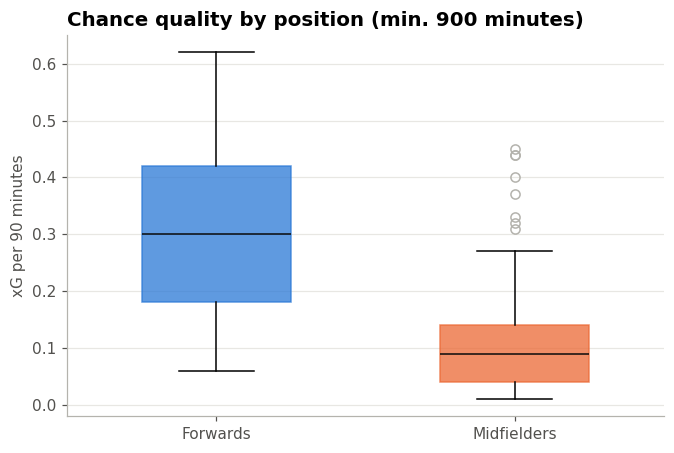

In [13]:
reg = df[df["Mins"] >= 900]
fw = reg.loc[reg["Main_Position"] == "FW", "xG"]
mf = reg.loc[reg["Main_Position"] == "MF", "xG"]
print(f"Forwards:    n = {len(fw)}, mean xG/90 = {fw.mean():.2f}")
print(f"Midfielders: n = {len(mf)}, mean xG/90 = {mf.mean():.2f}")

t_stat, p_value = stats.ttest_ind(fw, mf, equal_var=False)
print(f"t = {t_stat:.2f}, p = {p_value:.1e}")

fig, ax = plt.subplots(figsize=(7, 4.5))
parts = ax.boxplot([fw, mf], tick_labels=["Forwards", "Midfielders"], widths=0.5, patch_artist=True,
                   medianprops={"color": INK}, flierprops={"markeredgecolor": GREY})
for patch, c in zip(parts["boxes"], [BLUE, ORANGE]):
    patch.set(facecolor=c, alpha=0.75, edgecolor=c)
ax.set(ylabel="xG per 90 minutes", title="Chance quality by position (min. 900 minutes)")
ax.grid(axis="x", visible=False)
plt.show()

p is far below 0.05, so we reject H₀: forwards get clearly better chances, about 0.32 xG per 90
against 0.11 for midfielders.

## 8. Finding player roles with PCA and k-means

Positions in the data are coarse (DF, MF, FW). Can the numbers alone find more useful roles?

For every outfield player with at least 900 minutes I build a per-90 profile: goals, assists, xG, xA,
passes attempted, pass completion and cards. Then:
- Standardise each stat (mean 0, standard deviation 1), so passes (≈ 50 per 90) don't drown out goals (≈ 0.1).
- k-means groups players with similar profiles into 4 clusters.
- PCA squeezes the 7 stats into 2 axes for plotting. The axes are the eigenvectors of the stats'
  covariance matrix, i.e. the directions where players differ the most.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

out = df[(df["Mins"] >= 900) & (df["Main_Position"] != "GK")].copy()
per90 = lambda col: out[col] / out["Mins"] * 90
profile = pd.DataFrame({
    "Goals/90": per90("Goals"), "Assists/90": per90("Assists"),
    "xG/90": out["xG"], "xA/90": out["xA"],
    "Passes/90": per90("Passes_Attempted"), "Pass %": out["Perc_Passes_Completed"],
    "Cards/90": (out["Yellow_Cards"] + 2 * out["Red_Cards"]) / out["Mins"] * 90,
})
Z = StandardScaler().fit_transform(profile)

pca = PCA(n_components=2).fit(Z)
coords = pca.transform(Z)
out["PC1"], out["PC2"] = coords[:, 0], coords[:, 1]
print("Variance explained by the 2 axes:", pca.explained_variance_ratio_.round(2))
pd.DataFrame(pca.components_, columns=profile.columns, index=["PC1", "PC2"]).round(2)

Variance explained by the 2 axes: [0.48 0.19]


,Goals/90,Assists/90,xG/90,xA/90,Passes/90,Pass %,Cards/90
PC1,0.44,0.38,0.47,0.40,-0.32,-0.34,-0.25
PC2,-0.03,0.47,-0.06,0.47,0.61,0.42,-0.05


Reading the axes: PC1 loads on goals, assists, xG and xA, so it is *attacking output*. PC2 loads on
passes and pass completion, so it is *involvement in build-up play*. Together they keep about two thirds
of the information in the 7 stats.

In [15]:
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(Z)
out["Cluster"] = km.labels_
means = profile.groupby(out["Cluster"]).mean()

# Name the clusters from their average profile rather than by hand
names = {}
names[means["xG/90"].idxmax()] = "Goal threats"
names[means["Passes/90"].idxmax()] = "Ball players"
rest = means.drop(index=list(names))
names[rest["xA/90"].idxmax()] = "Creators"
names[rest["xA/90"].idxmin()] = "Defensive workers"
out["Role"] = out["Cluster"].map(names)

summary = profile.groupby(out["Role"]).mean().round(2)
summary["Players"] = out["Role"].value_counts()
summary

,Goals/90,Assists/90,xG/90,xA/90,Passes/90,Pass %,Cards/90,Players
Role,,,,,,,,
Ball players,0.05,0.04,0.06,0.05,62.80,86.54,0.18,100
Creators,0.13,0.21,0.14,0.18,47.28,76.94,0.10,52
Defensive workers,0.06,0.04,0.07,0.05,38.43,76.36,0.18,99
Goal threats,0.43,0.16,0.40,0.14,30.23,75.23,0.09,53


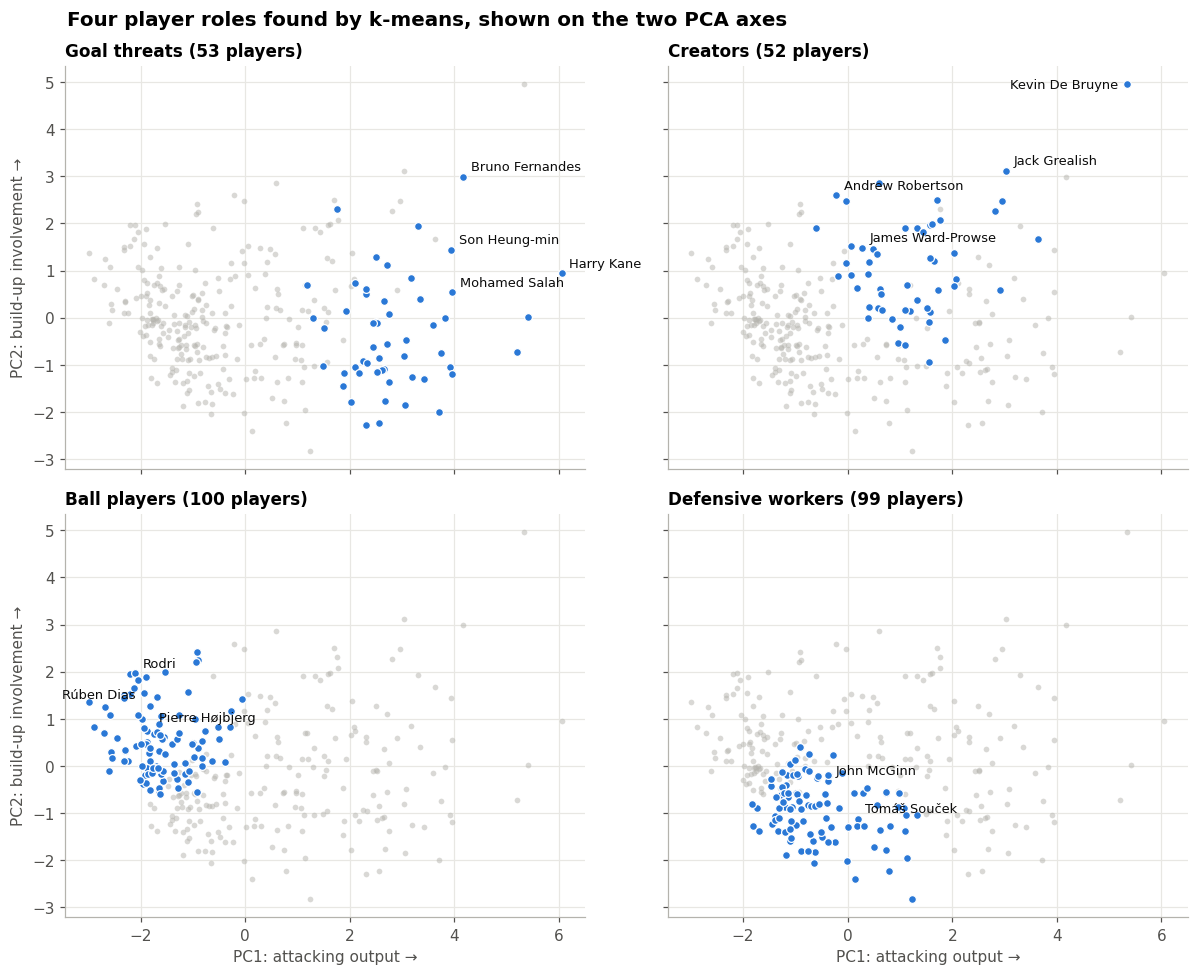

In [16]:
ROLES = ["Goal threats", "Creators", "Ball players", "Defensive workers"]
SHOW = {  # a few well-known names per role to anchor the map
    "Goal threats": ["Harry Kane", "Mohamed Salah", "Son Heung-min", "Bruno Fernandes"],
    "Creators": ["Kevin De Bruyne", "Andrew Robertson", "James Ward-Prowse", "Jack Grealish"],
    "Ball players": ["Rúben Dias", "Rodri", "Pierre Højbjerg"],
    "Defensive workers": ["Tomáš Souček", "John McGinn", "Conor Coady"],
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, role in zip(axes.flat, ROLES):
    inside = out["Role"] == role
    ax.scatter(out.loc[~inside, "PC1"], out.loc[~inside, "PC2"], s=14, color=GREY, alpha=0.5, linewidths=0)
    ax.scatter(out.loc[inside, "PC1"], out.loc[inside, "PC2"], s=26, color=BLUE, edgecolor="white", linewidth=0.8)
    for _, r in out[inside & out["Name"].isin(SHOW[role])].iterrows():
        dx, dy, ha = {"Kevin De Bruyne": (-6, -3, "right"), "Pierre Højbjerg": (6, -10, "left"),
                      "Rúben Dias": (-4, 6, "center")}.get(r["Name"], (5, 4, "left"))
        ax.annotate(r["Name"], (r["PC1"], r["PC2"]), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, fontsize=8.5, color=INK)
    ax.set_title(f"{role} ({inside.sum()} players)", fontsize=11)
for ax in axes[1]:
    ax.set_xlabel("PC1: attacking output →")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2: build-up involvement →")
fig.suptitle("Four player roles found by k-means, shown on the two PCA axes",
             x=0.06, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "player_roles.png")
plt.show()

The clusters line up with recognisable roles, even though the model never saw any positions:
- Goal threats: forwards and attacking midfielders like Kane, Salah and Bruno Fernandes.
- Creators: players who set up chances without scoring much. Kevin De Bruyne is the point in
  the far top right, the highest of all players on both axes. The group also includes attacking full-backs like
  Andrew Robertson and set-piece takers like James Ward-Prowse.
- Ball players: high pass volume and accuracy, mostly centre-backs and holding midfielders from
  possession teams.
- Defensive workers: little attacking output and fewer passes. Together with the ball players they
  pick up the most cards (about twice the rate of the attacking roles).

Positions mix across clusters. Robertson, for example, is listed as a defender but groups with the creators.

## 9. Comparing the stars

Radar charts for four of the season's best attackers. Each spoke is a percentile among the outfield
players above, so 90 means "better than 90% of regular Premier League outfield players".

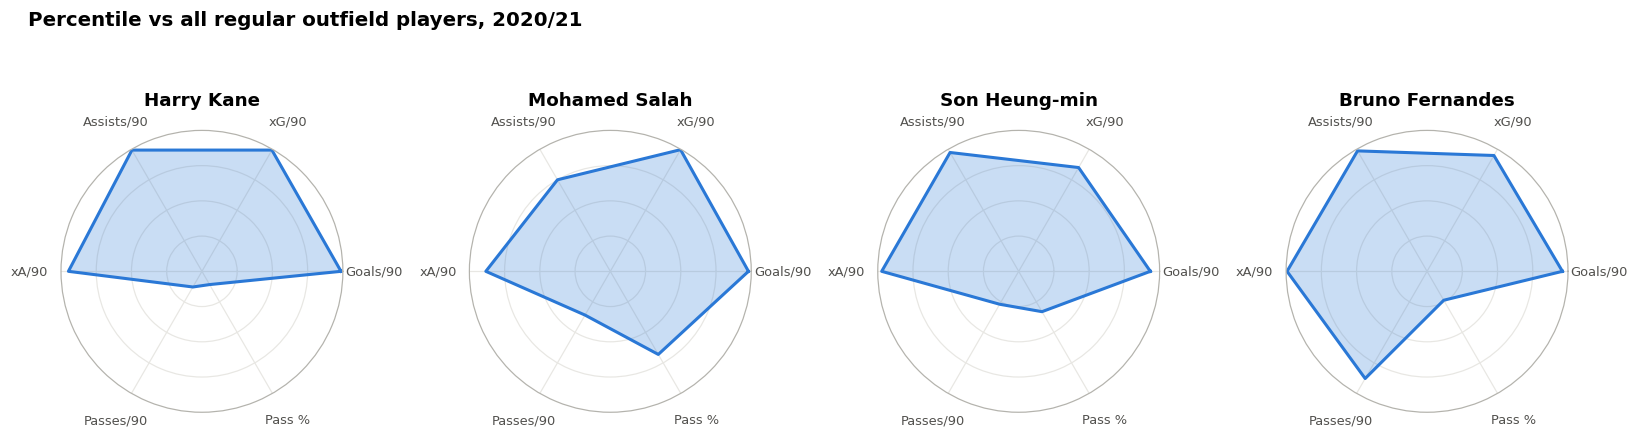

,Goals/90,xG/90,Assists/90,xA/90,Passes/90,Pass %
Name,,,,,,
Harry Kane,99.0,99.0,99.0,95.0,13.0,11.0
Mohamed Salah,98.0,100.0,75.0,88.0,36.0,68.0
Son Heung-min,93.0,85.0,97.0,97.0,27.0,33.0
Bruno Fernandes,96.0,95.0,99.0,99.0,88.0,24.0


In [17]:
STARS = ["Harry Kane", "Mohamed Salah", "Son Heung-min", "Bruno Fernandes"]
METRICS = ["Goals/90", "xG/90", "Assists/90", "xA/90", "Passes/90", "Pass %"]
pct = profile[METRICS].rank(pct=True) * 100
pct["Name"] = out["Name"]

angles = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False).tolist()
angles += angles[:1]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), subplot_kw={"polar": True})
for ax, star in zip(axes, STARS):
    vals = pct.loc[pct["Name"] == star, METRICS].iloc[0].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=BLUE, linewidth=2)
    ax.fill(angles, vals, color=BLUE, alpha=0.25)
    ax.set_xticks(angles[:-1], METRICS, fontsize=8.5, color=MUTED)
    ax.tick_params(axis="x", pad=10)
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50, 75], ["", "", ""])
    ax.spines["polar"].set_color(GREY)
    ax.set_title(star, fontsize=12, pad=16, loc="center")
fig.suptitle("Percentile vs all regular outfield players, 2020/21", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "star_radars.png")
plt.show()

pct.set_index("Name").loc[STARS].round(0)

All four sit near the top for goals and xG. The differences are in the build-up: Bruno Fernandes is
also heavily involved in passing, while Kane's profile shows a striker who also creates (top
percentiles for assists and xA), which matches his 14 assists in section 4.

## 10. Conclusions and limitations

Conclusions
- Over a season, xG predicts goals very well (slope ≈ 1, R² ≈ 0.87).
- The interesting players are the outliers: Son and Bale finished far above their chances,
  Werner and Vardy far below.
- At team level, Fulham and Sheffield United went down after scoring well below their xG, while
  Spurs and both Manchester clubs scored above theirs.
- Clustering per-90 profiles finds four roles (goal threats, creators, ball players, defensive
  workers) that cut across the official positions.

Limitations
- One season only. I can't tell whether over- or underperformance is skill or luck. With more
  seasons, I'd check whether the same players beat their xG year after year.
- xG and xA in the file are rounded to two decimals per 90, so season totals are approximate.
- Non-penalty xG uses a standard 0.76 xG per penalty, not the provider's exact value.
- The 8 players who moved clubs mid-season (e.g. Joe Willock, Arsenal → Newcastle) have one row per
  club, so their season is split in two.